In [3]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Add parent directory to path to import data configs
sys.path.append('../..')
from data.data_configs import *

print("Libraries imported successfully!")
print(f"Available subjects with EEG data: {len(os.listdir(LABELED_EEG_DATA_DIR))}")

Libraries imported successfully!
Available subjects with EEG data: 16


In [4]:
# Load training data from multiple subjects
def load_training_data(subjects=['P01', 'P05', 'P07'], pre_ms=500, post_ms=500):
    """Load and combine training data from multiple subjects"""
    all_X, all_y = [], []
    metadata = {}
    
    for subject in subjects:
        data_path = os.path.join(LABELED_EEG_DATA_DIR, subject, f"{pre_ms}_{post_ms}_training_data.npz")
        
        if os.path.exists(data_path):
            print(f"Loading {subject}...")
            data = np.load(data_path)
            
            X = data['X']  # Shape: (trials, channels, timepoints)
            y = data['y']  # Shape: (trials,)
            
            print(f"  - X shape: {X.shape}")
            print(f"  - y shape: {y.shape}")
            print(f"  - Labels distribution: {Counter(y)}")
            
            all_X.append(X)
            all_y.append(y)
            
            # Store metadata from first subject
            if not metadata:
                metadata = {
                    'channel_names': data['channel_names'],
                    'sampling_rate': data['sampling_rate'],
                    'time': data['time'],
                    'pre_window_ms': data['pre_window_ms'],
                    'post_window_ms': data['post_window_ms']
                }
        else:
            print(f"Warning: {data_path} not found!")
    
    if all_X:
        # Combine data from all subjects
        X_combined = np.concatenate(all_X, axis=0)
        y_combined = np.concatenate(all_y, axis=0)
        
        print(f"\nCombined data:")
        print(f"X shape: {X_combined.shape}")
        print(f"y shape: {y_combined.shape}")
        print(f"Overall label distribution: {Counter(y_combined)}")
        
        return X_combined, y_combined, metadata
    else:
        print("No data loaded!")
        return None, None, None

# Load the data
X, y, metadata = load_training_data()

Loading P01...
  - X shape: (3819, 32, 500)
  - y shape: (3819,)
  - Labels distribution: Counter({False: 2084, True: 1735})
Loading P05...
  - X shape: (2988, 32, 500)
  - y shape: (2988,)
  - Labels distribution: Counter({True: 1556, False: 1432})
Loading P07...
  - X shape: (3689, 32, 500)
  - y shape: (3689,)
  - Labels distribution: Counter({True: 1950, False: 1739})

Combined data:
X shape: (10496, 32, 500)
y shape: (10496,)
Overall label distribution: Counter({False: 5255, True: 5241})


In [5]:
# 1. Basic Data Quality Checks
print("=== BASIC DATA QUALITY CHECKS ===\n")

if X is not None and y is not None:
    # Check for NaN or infinite values
    print(f"1. NaN/Inf checks:")
    print(f"   - X contains NaN: {np.any(np.isnan(X))}")
    print(f"   - X contains Inf: {np.any(np.isinf(X))}")
    print(f"   - y contains NaN: {np.any(np.isnan(y))}")
    
    # Data ranges
    print(f"\n2. Data ranges:")
    print(f"   - X min: {X.min():.6f}")
    print(f"   - X max: {X.max():.6f}")
    print(f"   - X mean: {X.mean():.6f}")
    print(f"   - X std: {X.std():.6f}")
    
    # Label balance
    unique_labels, counts = np.unique(y, return_counts=True)
    print(f"\n3. Label distribution:")
    for label, count in zip(unique_labels, counts):
        percentage = count / len(y) * 100
        print(f"   - Label {label}: {count} samples ({percentage:.1f}%)")
    
    # Check if severely imbalanced
    if len(unique_labels) == 2:
        ratio = min(counts) / max(counts)
        print(f"   - Class balance ratio: {ratio:.3f}")
        if ratio < 0.1:
            print("   ⚠️ WARNING: Severely imbalanced dataset!")
        elif ratio < 0.3:
            print("   ⚠️ WARNING: Imbalanced dataset - consider rebalancing")
        else:
            print("   ✅ Reasonably balanced dataset")
    
    # Data type checks
    print(f"\n4. Data types:")
    print(f"   - X dtype: {X.dtype}")
    print(f"   - y dtype: {y.dtype}")
    
    # Metadata
    print(f"\n5. Metadata:")
    print(f"   - Channels: {len(metadata['channel_names'])}")
    print(f"   - Sampling rate: {metadata['sampling_rate']} Hz")
    print(f"   - Time window: {metadata['pre_window_ms']}ms to +{metadata['post_window_ms']}ms")
    print(f"   - Time points: {len(metadata['time'])}")
else:
    print("❌ No data loaded - cannot perform quality checks!")

=== BASIC DATA QUALITY CHECKS ===

1. NaN/Inf checks:
   - X contains NaN: False
   - X contains Inf: False
   - y contains NaN: False

2. Data ranges:
   - X min: -0.001001
   - X max: 0.001565
   - X mean: 0.000000
   - X std: 0.000010

3. Label distribution:
   - Label False: 5255 samples (50.1%)
   - Label True: 5241 samples (49.9%)
   - Class balance ratio: 0.997
   ✅ Reasonably balanced dataset

4. Data types:
   - X dtype: float64
   - y dtype: bool

5. Metadata:
   - Channels: 32
   - Sampling rate: 500.0 Hz
   - Time window: 500ms to +500ms
   - Time points: 500


=== DATA VISUALIZATION ===



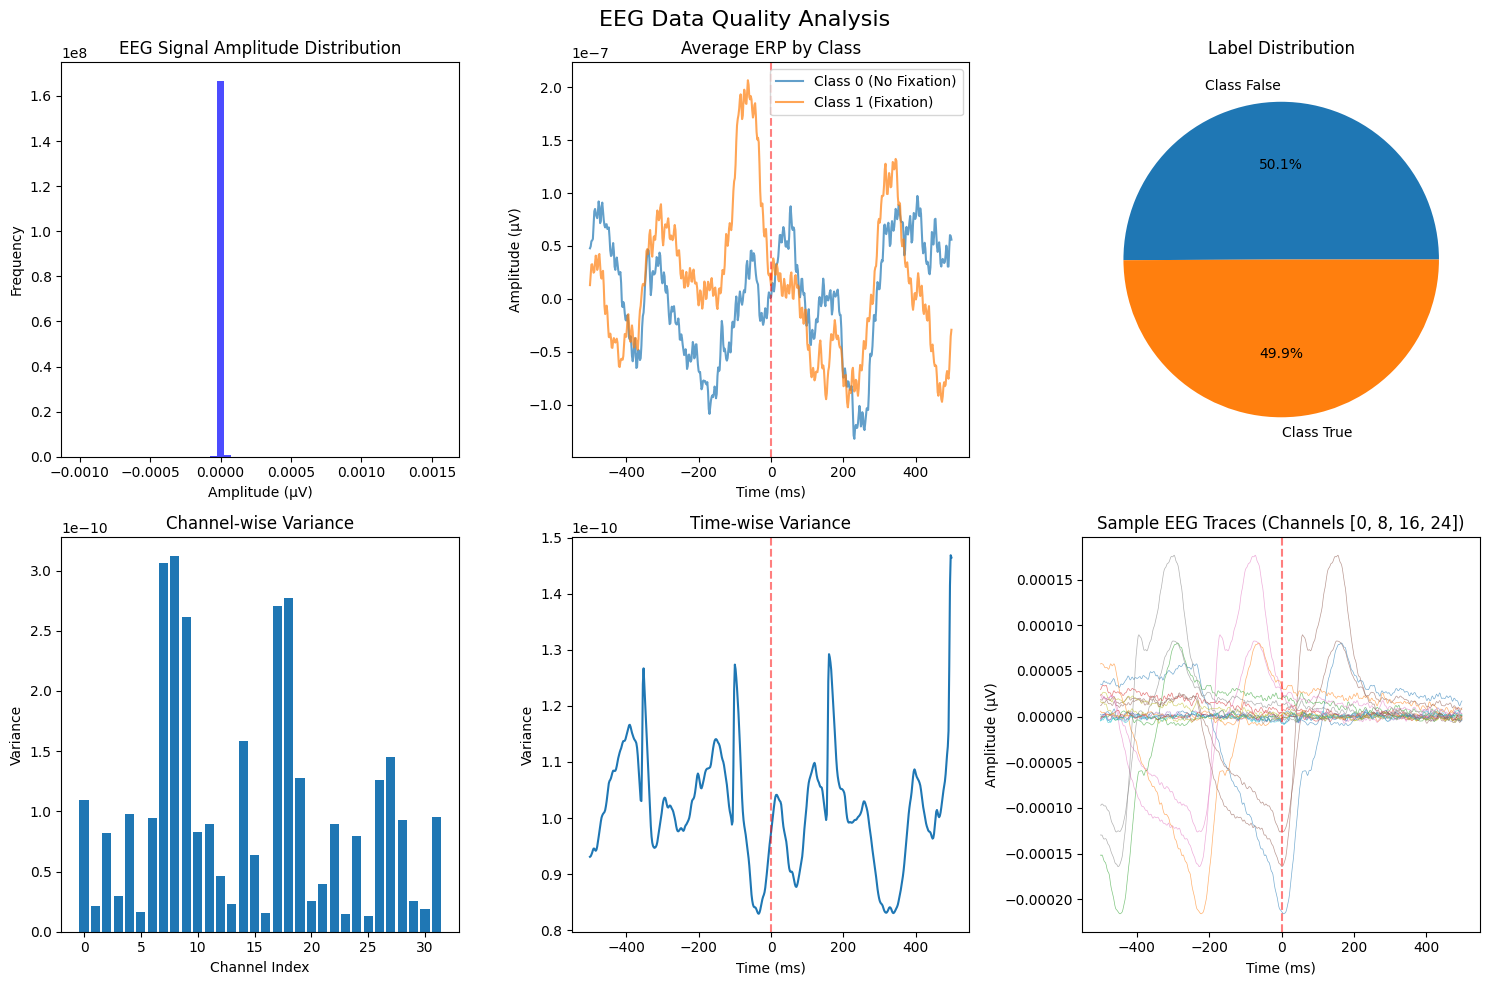

🔍 Visual Analysis Insights:
   - Signal range appears to be -0.0 to 0.0 μV
   - Most variable channels: [ 8  7 18]
   - Most variable time period: 496.0 ms


In [6]:
# 2. Data Visualization and Distribution Analysis
print("=== DATA VISUALIZATION ===\n")

if X is not None and y is not None:
    # Set up the plotting
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('EEG Data Quality Analysis', fontsize=16)
    
    # 1. Signal amplitude distribution
    axes[0, 0].hist(X.flatten(), bins=50, alpha=0.7, color='blue')
    axes[0, 0].set_title('EEG Signal Amplitude Distribution')
    axes[0, 0].set_xlabel('Amplitude (μV)')
    axes[0, 0].set_ylabel('Frequency')
    
    # 2. Average signal per class
    if len(np.unique(y)) == 2:
        class_0_data = X[y == False]
        class_1_data = X[y == True]
        
        # Average across trials and channels for each class
        avg_class_0 = np.mean(class_0_data, axis=(0, 1))  # Average over trials and channels
        avg_class_1 = np.mean(class_1_data, axis=(0, 1))
        
        axes[0, 1].plot(metadata['time'], avg_class_0, label='Class 0 (No Fixation)', alpha=0.7)
        axes[0, 1].plot(metadata['time'], avg_class_1, label='Class 1 (Fixation)', alpha=0.7)
        axes[0, 1].set_title('Average ERP by Class')
        axes[0, 1].set_xlabel('Time (ms)')
        axes[0, 1].set_ylabel('Amplitude (μV)')
        axes[0, 1].legend()
        axes[0, 1].axvline(x=0, color='red', linestyle='--', alpha=0.5, label='Event onset')
    
    # 3. Label distribution pie chart
    unique_labels, counts = np.unique(y, return_counts=True)
    axes[0, 2].pie(counts, labels=[f'Class {l}' for l in unique_labels], autopct='%1.1f%%')
    axes[0, 2].set_title('Label Distribution')
    
    # 4. Channel-wise variance
    channel_variance = np.var(X, axis=(0, 2))  # Variance across trials and time
    axes[1, 0].bar(range(len(channel_variance)), channel_variance)
    axes[1, 0].set_title('Channel-wise Variance')
    axes[1, 0].set_xlabel('Channel Index')
    axes[1, 0].set_ylabel('Variance')
    
    # 5. Time-wise variance (across trials and channels)
    time_variance = np.var(X, axis=(0, 1))
    axes[1, 1].plot(metadata['time'], time_variance)
    axes[1, 1].set_title('Time-wise Variance')
    axes[1, 1].set_xlabel('Time (ms)')
    axes[1, 1].set_ylabel('Variance')
    axes[1, 1].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    
    # 6. Sample EEG traces for a few trials
    n_sample_trials = min(5, X.shape[0])
    sample_channels = [0, 8, 16, 24]  # Sample a few channels
    
    for i, ch in enumerate(sample_channels):
        if ch < X.shape[1]:
            for trial in range(n_sample_trials):
                axes[1, 2].plot(metadata['time'], X[trial, ch, :], alpha=0.6, linewidth=0.5)
    
    axes[1, 2].set_title(f'Sample EEG Traces (Channels {sample_channels})')
    axes[1, 2].set_xlabel('Time (ms)')
    axes[1, 2].set_ylabel('Amplitude (μV)')
    axes[1, 2].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    # Print some insights
    print("🔍 Visual Analysis Insights:")
    print(f"   - Signal range appears to be {X.min():.1f} to {X.max():.1f} μV")
    print(f"   - Most variable channels: {np.argsort(channel_variance)[-3:][::-1]}")
    print(f"   - Most variable time period: {metadata['time'][np.argmax(time_variance)]:.1f} ms")
else:
    print("❌ Cannot create visualizations - no data loaded")

In [7]:
# 3. Statistical Significance Tests
print("=== STATISTICAL SIGNIFICANCE TESTS ===\n")

if X is not None and y is not None and len(np.unique(y)) == 2:
    from scipy import stats
    
    # Test if there are significant differences between classes
    class_0_data = X[y == False]
    class_1_data = X[y == True]
    
    print(f"Testing differences between classes:")
    print(f"Class 0 (No Fixation): {len(class_0_data)} trials")
    print(f"Class 1 (Fixation): {len(class_1_data)} trials")
    
    # Test differences in mean amplitude across all channels and time points
    flat_class_0 = class_0_data.reshape(len(class_0_data), -1).mean(axis=1)
    flat_class_1 = class_1_data.reshape(len(class_1_data), -1).mean(axis=1)
    
    t_stat, p_value = stats.ttest_ind(flat_class_0, flat_class_1)
    print(f"\nOverall amplitude difference (t-test):")
    print(f"   - t-statistic: {t_stat:.4f}")
    print(f"   - p-value: {p_value:.6f}")
    
    if p_value < 0.001:
        print("   ✅ HIGHLY SIGNIFICANT difference between classes!")
    elif p_value < 0.05:
        print("   ✅ Significant difference between classes!")
    else:
        print("   ⚠️ NO significant difference found - this could explain poor learning!")
    
    # Test temporal differences (around event onset)
    event_onset_idx = np.argmin(np.abs(metadata['time']))  # Find time point closest to 0
    window_start = max(0, event_onset_idx - 50)  # 50 samples before onset
    window_end = min(len(metadata['time']), event_onset_idx + 150)  # 150 samples after onset
    
    # Extract data around event onset
    onset_class_0 = class_0_data[:, :, window_start:window_end].mean(axis=1).flatten()
    onset_class_1 = class_1_data[:, :, window_start:window_end].mean(axis=1).flatten()
    
    t_stat_onset, p_value_onset = stats.ttest_ind(onset_class_0, onset_class_1)
    print(f"\nEvent-locked difference (around onset):")
    print(f"   - t-statistic: {t_stat_onset:.4f}")
    print(f"   - p-value: {p_value_onset:.6f}")
    
    if p_value_onset < 0.001:
        print("   ✅ HIGHLY SIGNIFICANT event-related difference!")
    elif p_value_onset < 0.05:
        print("   ✅ Significant event-related difference!")
    else:
        print("   ⚠️ NO significant event-related difference!")
        
    # Effect size (Cohen's d)
    pooled_std = np.sqrt(((len(flat_class_0) - 1) * np.var(flat_class_0, ddof=1) + 
                         (len(flat_class_1) - 1) * np.var(flat_class_1, ddof=1)) / 
                        (len(flat_class_0) + len(flat_class_1) - 2))
    cohens_d = (np.mean(flat_class_1) - np.mean(flat_class_0)) / pooled_std
    
    print(f"\nEffect size (Cohen's d): {cohens_d:.4f}")
    if abs(cohens_d) > 0.8:
        print("   ✅ Large effect size - good separability!")
    elif abs(cohens_d) > 0.5:
        print("   ⚠️ Medium effect size - moderate separability")
    elif abs(cohens_d) > 0.2:
        print("   ⚠️ Small effect size - difficult separation")
    else:
        print("   ❌ Very small effect size - classes barely distinguishable!")
        
else:
    print("❌ Cannot perform statistical tests - need binary classification data")

=== STATISTICAL SIGNIFICANCE TESTS ===

Testing differences between classes:
Class 0 (No Fixation): 5255 trials
Class 1 (Fixation): 5241 trials

Overall amplitude difference (t-test):
   - t-statistic: -0.7184
   - p-value: 0.472501
   ⚠️ NO significant difference found - this could explain poor learning!

Event-locked difference (around onset):
   - t-statistic: -4.1930
   - p-value: 0.000028
   ✅ HIGHLY SIGNIFICANT event-related difference!

Effect size (Cohen's d): 0.0140
   ❌ Very small effect size - classes barely distinguishable!


In [8]:
# 4. Simple Machine Learning Test
print("=== SIMPLE MACHINE LEARNING TEST ===\n")

if X is not None and y is not None:
    # Reshape data for traditional ML (flatten spatial-temporal features)
    X_flattened = X.reshape(X.shape[0], -1)  # (trials, channels*timepoints)
    
    print(f"Flattened features shape: {X_flattened.shape}")
    
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(
        X_flattened, y, test_size=0.2, random_state=42, stratify=y
    )
    
    print(f"Training set: {X_train.shape[0]} samples")
    print(f"Test set: {X_test.shape[0]} samples")
    
    # Test with simple logistic regression
    print("\n1. Logistic Regression (baseline):")
    lr = LogisticRegression(random_state=42, max_iter=1000)
    lr.fit(X_train, y_train)
    
    train_acc = lr.score(X_train, y_train)
    test_acc = lr.score(X_test, y_test)
    
    print(f"   - Training accuracy: {train_acc:.4f}")
    print(f"   - Test accuracy: {test_acc:.4f}")
    
    if test_acc > 0.6:
        print("   ✅ Good baseline performance - data is learnable!")
    elif test_acc > 0.55:
        print("   ⚠️ Modest baseline performance - data might be learnable")
    else:
        print("   ❌ Poor baseline performance - data might not be learnable!")
    
    # Predictions and confusion matrix
    y_pred = lr.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n2. Classification Report:")
    print(classification_report(y_test, y_pred))
    
    print(f"3. Confusion Matrix:")
    print(cm)
    
    # Check for data leakage or overfitting signs
    if train_acc - test_acc > 0.2:
        print("\n⚠️ WARNING: Large train-test gap suggests potential overfitting or data leakage!")
    elif train_acc - test_acc < 0.05:
        print("\n✅ Good generalization - minimal overfitting")
    
    # Feature importance (top contributing features)
    feature_importance = np.abs(lr.coef_[0])
    top_features_idx = np.argsort(feature_importance)[-10:][::-1]
    
    print(f"\n4. Top 10 most important features (channel_timepoint):")
    n_timepoints = X.shape[2]
    for i, feat_idx in enumerate(top_features_idx):
        channel_idx = feat_idx // n_timepoints
        time_idx = feat_idx % n_timepoints
        time_ms = metadata['time'][time_idx]
        importance = feature_importance[feat_idx]
        channel_name = metadata['channel_names'][channel_idx] if channel_idx < len(metadata['channel_names']) else f"Ch{channel_idx}"
        print(f"   {i+1}. {channel_name} at {time_ms:.1f}ms (importance: {importance:.4f})")

else:
    print("❌ Cannot perform ML test - no data loaded")

=== SIMPLE MACHINE LEARNING TEST ===

Flattened features shape: (10496, 16000)
Training set: 8396 samples
Test set: 2100 samples

1. Logistic Regression (baseline):
   - Training accuracy: 0.5007
   - Test accuracy: 0.5005
   ❌ Poor baseline performance - data might not be learnable!

2. Classification Report:
              precision    recall  f1-score   support

       False       0.50      1.00      0.67      1051
        True       0.00      0.00      0.00      1049

    accuracy                           0.50      2100
   macro avg       0.25      0.50      0.33      2100
weighted avg       0.25      0.50      0.33      2100

3. Confusion Matrix:
[[1051    0]
 [1049    0]]

✅ Good generalization - minimal overfitting

4. Top 10 most important features (channel_timepoint):
   1. CP5 at -124.0ms (importance: 0.0000)
   2. CP5 at -122.0ms (importance: 0.0000)
   3. CP5 at -120.0ms (importance: 0.0000)
   4. CP5 at -118.0ms (importance: 0.0000)
   5. CP5 at -116.0ms (importance: 0.000

~/Code/Eye_EEG/.eye_eeg_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
~/Code/Eye_EEG/.eye_eeg_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
~/Code/Eye_EEG/.eye_eeg_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [9]:
# 5. EEGNet-specific Data Checks
print("=== EEGNET-SPECIFIC CHECKS ===\n")

if X is not None and y is not None:
    print("1. Data format compatibility:")
    print(f"   - Input shape: {X.shape} (should be: trials, channels, timepoints)")
    print(f"   - Expected for EEGNet: (n_trials, n_channels, n_timepoints)")
    
    # Check if data needs reshaping for Keras/TensorFlow
    if len(X.shape) == 3:
        print("   ✅ Correct 3D format for EEGNet")
    else:
        print("   ❌ Incorrect format - EEGNet needs 3D input")
    
    print(f"\n2. Recommended EEGNet parameters based on your data:")
    n_channels = X.shape[1]
    n_timepoints = X.shape[2]
    sampling_rate = metadata['sampling_rate']
    
    print(f"   - Chans: {n_channels}")
    print(f"   - Samples: {n_timepoints}")
    print(f"   - Sampling rate: {sampling_rate} Hz")
    
    # Suggest kernel sizes
    temporal_kernel = min(int(sampling_rate * 0.125), n_timepoints // 2)  # ~125ms or half the data
    print(f"   - Suggested temporal kernel size: {temporal_kernel}")
    print(f"   - Suggested spatial kernel size: 1 (standard for EEGNet)")
    
    print(f"\n3. Data preprocessing checks:")
    
    # Check if data is standardized
    channel_means = np.mean(X, axis=(0, 2))  # Mean across trials and time for each channel
    channel_stds = np.std(X, axis=(0, 2))   # Std across trials and time for each channel
    
    if np.all(np.abs(channel_means) < 1e-6) and np.all(np.abs(channel_stds - 1) < 1e-1):
        print("   ✅ Data appears to be standardized (zero mean, unit variance)")
    else:
        print("   ⚠️ Data may not be standardized - consider z-score normalization")
        print(f"     Channel means range: {channel_means.min():.4f} to {channel_means.max():.4f}")
        print(f"     Channel stds range: {channel_stds.min():.4f} to {channel_stds.max():.4f}")
    
    # Check for artifacts or extreme values
    extreme_threshold = 5 * np.std(X)
    extreme_count = np.sum(np.abs(X) > extreme_threshold)
    extreme_percentage = extreme_count / X.size * 100
    
    print(f"\n4. Artifact detection:")
    print(f"   - Values beyond ±5σ: {extreme_count} ({extreme_percentage:.2f}% of data)")
    
    if extreme_percentage > 5:
        print("   ⚠️ High percentage of extreme values - check for artifacts!")
    elif extreme_percentage > 1:
        print("   ⚠️ Some extreme values present - normal but monitor")
    else:
        print("   ✅ Low percentage of extreme values - good data quality")
    
    # Memory and computational requirements
    memory_mb = X.nbytes / (1024**2)
    print(f"\n5. Computational requirements:")
    print(f"   - Data size in memory: {memory_mb:.1f} MB")
    
    if memory_mb > 1000:
        print("   ⚠️ Large dataset - consider batch processing")
    else:
        print("   ✅ Manageable dataset size")
        
    # Batch size recommendations
    n_trials = X.shape[0]
    suggested_batch_sizes = [16, 32, 64, 128]
    valid_batch_sizes = [bs for bs in suggested_batch_sizes if n_trials >= bs * 5]  # At least 5 batches
    
    if valid_batch_sizes:
        print(f"   - Suggested batch sizes: {valid_batch_sizes}")
    else:
        print(f"   - Small dataset - use batch size of {min(16, n_trials//2)}")

else:
    print("❌ Cannot perform EEGNet checks - no data loaded")

=== EEGNET-SPECIFIC CHECKS ===

1. Data format compatibility:
   - Input shape: (10496, 32, 500) (should be: trials, channels, timepoints)
   - Expected for EEGNet: (n_trials, n_channels, n_timepoints)
   ✅ Correct 3D format for EEGNet

2. Recommended EEGNet parameters based on your data:
   - Chans: 32
   - Samples: 500
   - Sampling rate: 500.0 Hz
   - Suggested temporal kernel size: 62
   - Suggested spatial kernel size: 1 (standard for EEGNet)

3. Data preprocessing checks:
   ⚠️ Data may not be standardized - consider z-score normalization
     Channel means range: -0.0000 to 0.0000
     Channel stds range: 0.0000 to 0.0000

4. Artifact detection:
   - Values beyond ±5σ: 550674 (0.33% of data)
   ✅ Low percentage of extreme values - good data quality

5. Computational requirements:
   - Data size in memory: 1281.2 MB
   ⚠️ Large dataset - consider batch processing
   - Suggested batch sizes: [16, 32, 64, 128]


In [10]:
# 6. Final Recommendations and Summary
print("=== FINAL RECOMMENDATIONS ===\n")

if X is not None and y is not None:
    # Collect all the issues and recommendations
    issues = []
    recommendations = []
    
    # Check data quality issues
    if np.any(np.isnan(X)) or np.any(np.isinf(X)):
        issues.append("❌ Data contains NaN or infinite values")
        recommendations.append("Clean data by removing or imputing NaN/Inf values")
    
    # Check class balance
    unique_labels, counts = np.unique(y, return_counts=True)
    if len(unique_labels) == 2:
        ratio = min(counts) / max(counts)
        if ratio < 0.1:
            issues.append("❌ Severely imbalanced classes")
            recommendations.append("Use class weights, SMOTE, or resampling techniques")
        elif ratio < 0.3:
            issues.append("⚠️ Moderately imbalanced classes")
            recommendations.append("Consider using class weights in your loss function")
    
    # Check sample size
    n_samples = X.shape[0]
    if n_samples < 100:
        issues.append("❌ Very small dataset")
        recommendations.append("Collect more data or use data augmentation")
    elif n_samples < 500:
        issues.append("⚠️ Small dataset")
        recommendations.append("Use regularization and careful validation")
    
    # Check if there were statistical differences
    if len(np.unique(y)) == 2:
        class_0_data = X[y == False].reshape(len(X[y == False]), -1).mean(axis=1)
        class_1_data = X[y == True].reshape(len(X[y == True]), -1).mean(axis=1)
        from scipy import stats
        _, p_value = stats.ttest_ind(class_0_data, class_1_data)
        
        if p_value > 0.05:
            issues.append("❌ No significant difference between classes")
            recommendations.append("Check data labeling, preprocessing, or feature extraction")
    
    # Print issues
    if issues:
        print("🚨 IDENTIFIED ISSUES:")
        for issue in issues:
            print(f"   {issue}")
    else:
        print("✅ NO MAJOR ISSUES IDENTIFIED")
    
    print(f"\n💡 RECOMMENDATIONS:")
    if recommendations:
        for rec in recommendations:
            print(f"   • {rec}")
    
    # Always provide standard recommendations
    print(f"   • Use train/validation/test splits (e.g., 70/15/15)")
    print(f"   • Monitor for overfitting with early stopping")
    print(f"   • Start with a simple EEGNet architecture")
    print(f"   • Use appropriate learning rates (start with 1e-3)")
    print(f"   • Consider data augmentation if dataset is small")
    
    print(f"\n📊 DATA SUMMARY:")
    print(f"   • Total samples: {n_samples}")
    print(f"   • Features: {X.shape[1]} channels × {X.shape[2]} timepoints = {X.shape[1]*X.shape[2]} features")
    print(f"   • Classes: {len(unique_labels)} ({dict(zip(unique_labels, counts))})")
    print(f"   • Data range: [{X.min():.2f}, {X.max():.2f}]")
    print(f"   • Memory footprint: {X.nbytes/(1024**2):.1f} MB")
    
    print(f"\n🎯 LIKELIHOOD OF SUCCESSFUL TRAINING:")
    
    # Simple scoring system
    score = 0
    max_score = 5
    
    # Data quality (0-1 points)
    if not (np.any(np.isnan(X)) or np.any(np.isinf(X))):
        score += 1
    
    # Sample size (0-1 points)  
    if n_samples >= 500:
        score += 1
    elif n_samples >= 100:
        score += 0.5
    
    # Class balance (0-1 points)
    if len(unique_labels) == 2 and min(counts) / max(counts) >= 0.3:
        score += 1
    elif len(unique_labels) == 2 and min(counts) / max(counts) >= 0.1:
        score += 0.5
    
    # Statistical significance (0-1 points)
    if len(np.unique(y)) == 2 and p_value <= 0.05:
        score += 1
    elif len(np.unique(y)) == 2 and p_value <= 0.1:
        score += 0.5
    
    # Feature richness (0-1 points)
    n_features = X.shape[1] * X.shape[2]
    if n_features >= 1000:
        score += 1
    elif n_features >= 500:
        score += 0.5
    
    percentage = (score / max_score) * 100
    
    if percentage >= 80:
        print(f"   🟢 HIGH ({percentage:.0f}%) - Data looks good for training!")
    elif percentage >= 60:
        print(f"   🟡 MODERATE ({percentage:.0f}%) - Should work with proper tuning")
    elif percentage >= 40:
        print(f"   🟠 LOW ({percentage:.0f}%) - May need significant preprocessing/augmentation")
    else:
        print(f"   🔴 VERY LOW ({percentage:.0f}%) - Substantial data issues need addressing")

else:
    print("❌ Cannot provide recommendations - no data was loaded")

=== FINAL RECOMMENDATIONS ===

🚨 IDENTIFIED ISSUES:
   ❌ No significant difference between classes

💡 RECOMMENDATIONS:
   • Check data labeling, preprocessing, or feature extraction
   • Use train/validation/test splits (e.g., 70/15/15)
   • Monitor for overfitting with early stopping
   • Start with a simple EEGNet architecture
   • Use appropriate learning rates (start with 1e-3)
   • Consider data augmentation if dataset is small

📊 DATA SUMMARY:
   • Total samples: 10496
   • Features: 32 channels × 500 timepoints = 16000 features
   • Classes: 2 ({False: 5255, True: 5241})
   • Data range: [-0.00, 0.00]
   • Memory footprint: 1281.2 MB

🎯 LIKELIHOOD OF SUCCESSFUL TRAINING:
   🟢 HIGH (80%) - Data looks good for training!


=== DETAILED ERP ANALYSIS ===

Non-target trials: 5255
Target trials: 5241
ERP shapes: (32, 500)


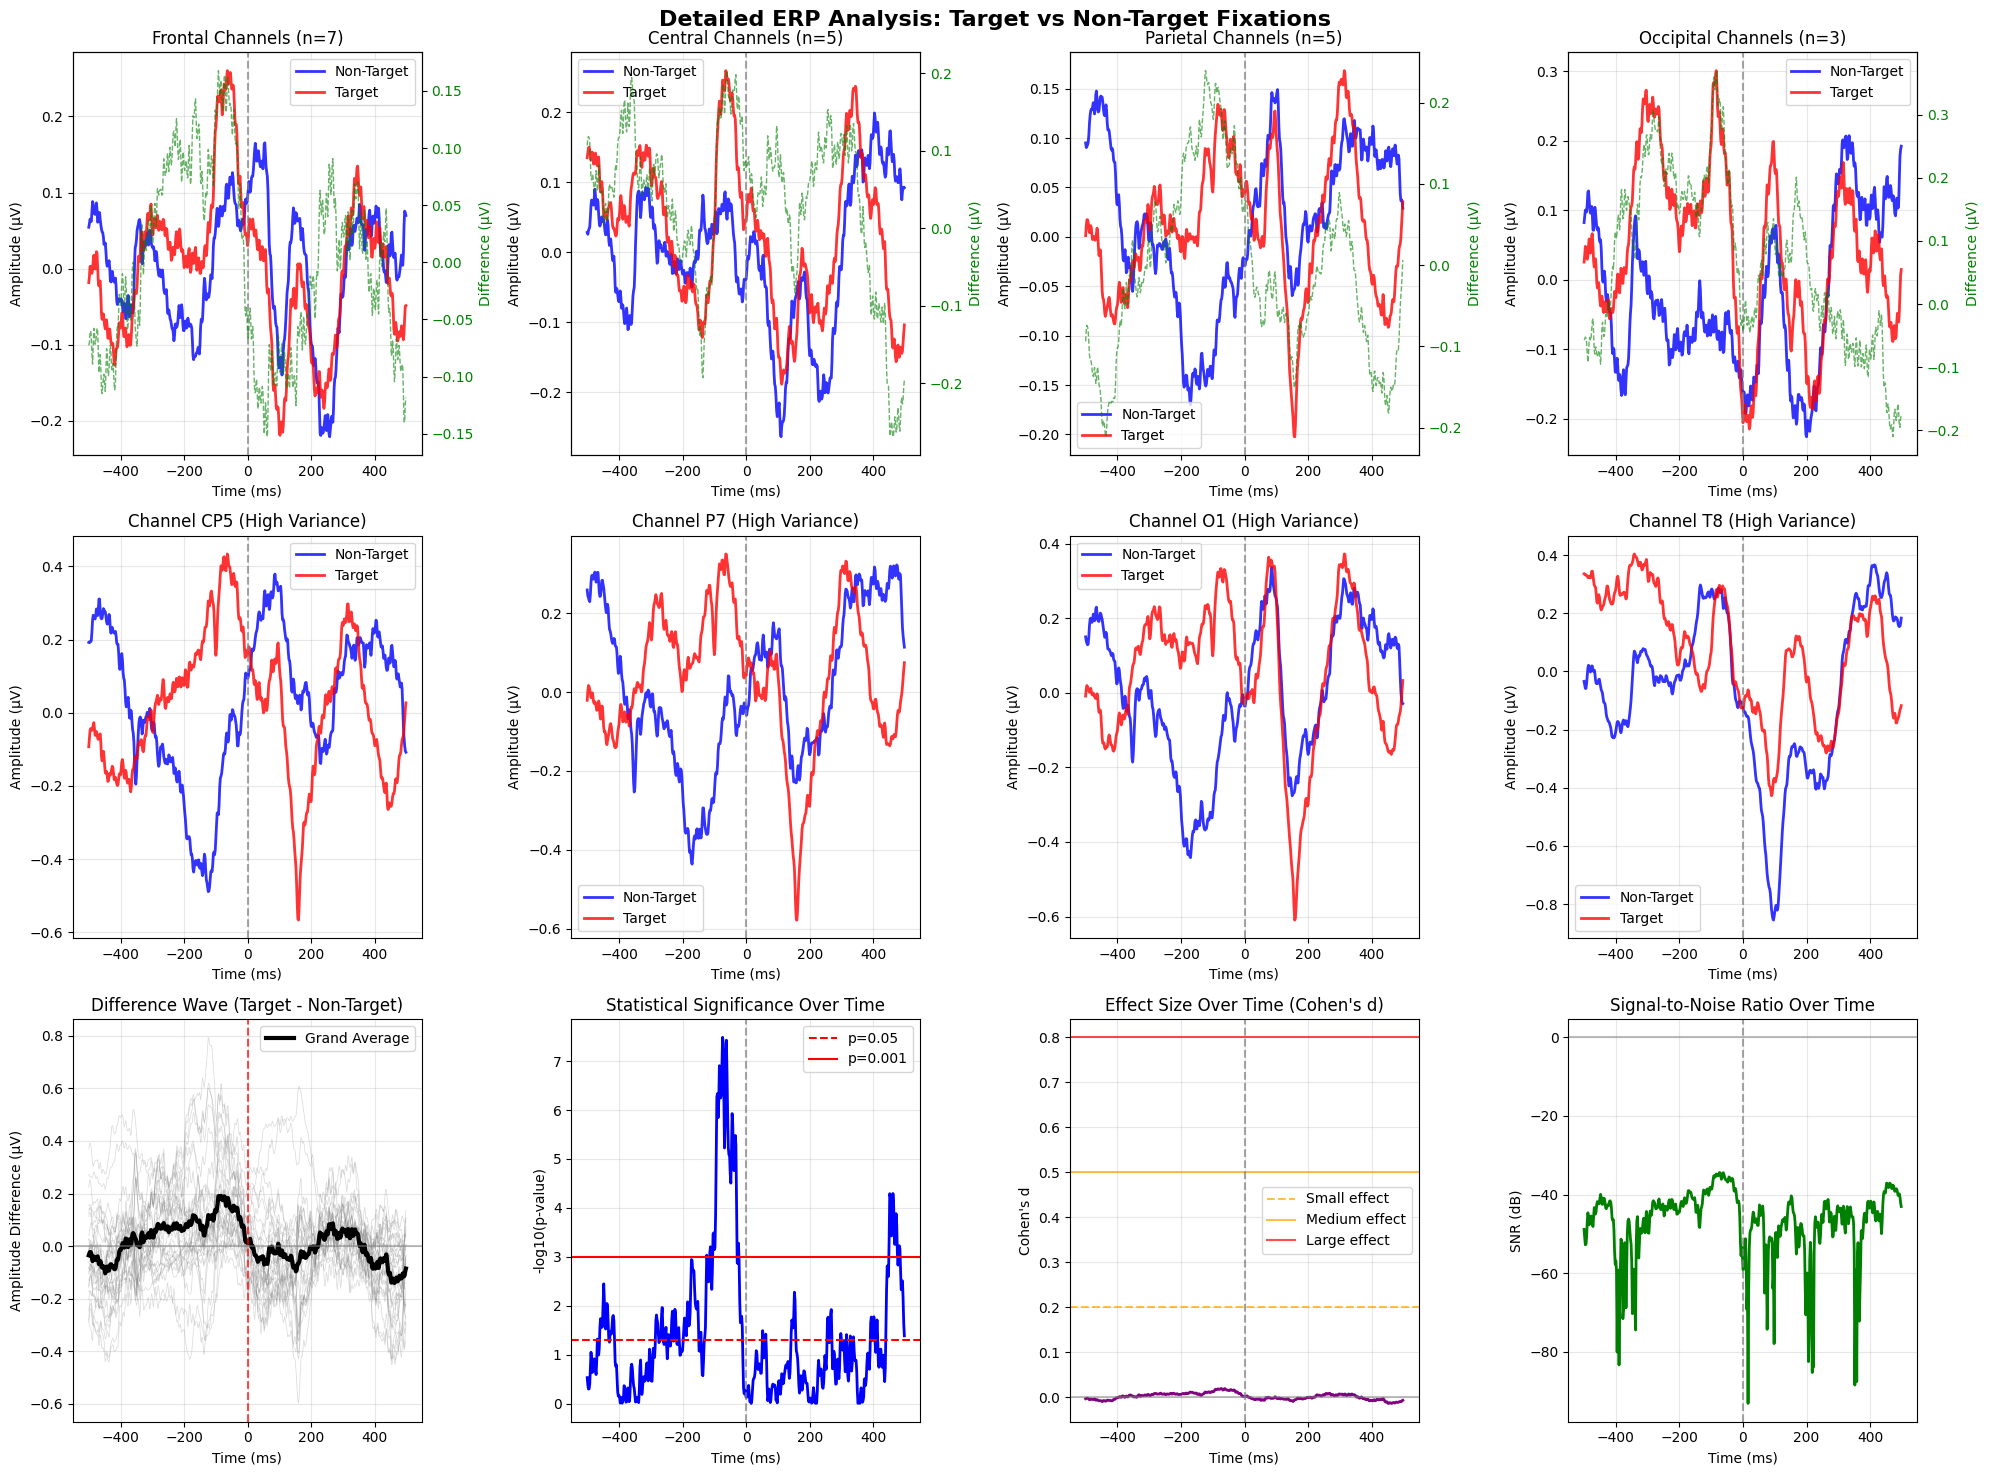


🔍 ERP ANALYSIS SUMMARY:
   - Peak difference amplitude: 0.191 μV
   - Time of peak difference: -84.0 ms
   - Maximum Cohen's d: 0.0191
   - Time of max effect: -74.0 ms
   - Minimum p-value: 3.25e-08
   - Time of min p-value: -74.0 ms


In [11]:
# =============================================================================
# DETAILED ERP ANALYSIS - Target vs Non-Target Fixations
# =============================================================================

print("=== DETAILED ERP ANALYSIS ===\n")

# Separate the data by class
non_target_data = X[y == False]  # Class 0 - No fixation
target_data = X[y == True]       # Class 1 - Fixation

print(f"Non-target trials: {len(non_target_data)}")
print(f"Target trials: {len(target_data)}")

# Calculate grand average ERPs for each class
non_target_erp = np.mean(non_target_data, axis=0)  # Average across trials: (channels, timepoints)
target_erp = np.mean(target_data, axis=0)          # Average across trials: (channels, timepoints)

print(f"ERP shapes: {non_target_erp.shape}")

# Create comprehensive ERP visualization
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle('Detailed ERP Analysis: Target vs Non-Target Fixations', fontsize=16, fontweight='bold')

# Define channel groups for systematic analysis
channel_groups = {
    'Frontal': ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8'],
    'Central': ['T7', 'C3', 'Cz', 'C4', 'T8'],  
    'Parietal': ['P7', 'P3', 'Pz', 'P4', 'P8'],
    'Occipital': ['O1', 'Oz', 'O2']
}

# Plot 1-4: Channel group averages
plot_idx = 0
for group_name, channels in channel_groups.items():
    if plot_idx < 4:
        ax = axes[0, plot_idx]
        
        # Find indices of channels in this group
        channel_indices = []
        for ch in channels:
            if ch in metadata['channel_names']:
                channel_indices.append(list(metadata['channel_names']).index(ch))
        
        if channel_indices:
            # Average across channels in this group
            non_target_group = np.mean(non_target_erp[channel_indices, :], axis=0)
            target_group = np.mean(target_erp[channel_indices, :], axis=0)
            
            ax.plot(metadata['time'], non_target_group * 1e6, 'b-', linewidth=2, label='Non-Target', alpha=0.8)
            ax.plot(metadata['time'], target_group * 1e6, 'r-', linewidth=2, label='Target', alpha=0.8)
            ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
            ax.set_title(f'{group_name} Channels (n={len(channel_indices)})')
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Amplitude (μV)')
            ax.legend()
            ax.grid(True, alpha=0.3)
            
            # Add difference curve
            ax2 = ax.twinx()
            diff = (target_group - non_target_group) * 1e6
            ax2.plot(metadata['time'], diff, 'g--', alpha=0.6, linewidth=1, label='Difference')
            ax2.set_ylabel('Difference (μV)', color='g')
            ax2.tick_params(axis='y', labelcolor='g')
            
        plot_idx += 1

# Plot 5-8: Individual high-variance channels
high_var_channels = np.argsort(np.var(target_erp - non_target_erp, axis=1))[-4:][::-1]

for i, ch_idx in enumerate(high_var_channels):
    ax = axes[1, i]
    channel_name = metadata['channel_names'][ch_idx]
    
    ax.plot(metadata['time'], non_target_erp[ch_idx, :] * 1e6, 'b-', linewidth=2, label='Non-Target', alpha=0.8)
    ax.plot(metadata['time'], target_erp[ch_idx, :] * 1e6, 'r-', linewidth=2, label='Target', alpha=0.8)
    ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f'Channel {channel_name} (High Variance)')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Amplitude (μV)')
    ax.legend()
    ax.grid(True, alpha=0.3)

# Plot 9: Difference waveform (Target - Non-Target) across all channels
ax = axes[2, 0]
difference_erp = target_erp - non_target_erp
# Plot all channels as light gray lines
for ch in range(difference_erp.shape[0]):
    ax.plot(metadata['time'], difference_erp[ch, :] * 1e6, 'gray', alpha=0.3, linewidth=0.5)
# Plot grand average difference
grand_avg_diff = np.mean(difference_erp, axis=0)
ax.plot(metadata['time'], grand_avg_diff * 1e6, 'k-', linewidth=3, label='Grand Average')
ax.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax.axvline(x=0, color='red', linestyle='--', alpha=0.7)
ax.set_title('Difference Wave (Target - Non-Target)')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude Difference (μV)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 10: Statistical significance over time
ax = axes[2, 1]
from scipy import stats

t_stats = []
p_values = []
for t in range(X.shape[2]):  # For each time point
    non_target_timepoint = non_target_data[:, :, t].flatten()
    target_timepoint = target_data[:, :, t].flatten()
    t_stat, p_val = stats.ttest_ind(non_target_timepoint, target_timepoint)
    t_stats.append(t_stat)
    p_values.append(p_val)

ax.plot(metadata['time'], -np.log10(p_values), 'b-', linewidth=2)
ax.axhline(y=-np.log10(0.05), color='red', linestyle='--', label='p=0.05')
ax.axhline(y=-np.log10(0.001), color='red', linestyle='-', label='p=0.001')
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
ax.set_title('Statistical Significance Over Time')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('-log10(p-value)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 11: Effect size (Cohen's d) over time
ax = axes[2, 2]
cohens_d_time = []
for t in range(X.shape[2]):
    non_target_t = non_target_data[:, :, t].flatten()
    target_t = target_data[:, :, t].flatten()
    
    pooled_std = np.sqrt(((len(non_target_t) - 1) * np.var(non_target_t, ddof=1) + 
                         (len(target_t) - 1) * np.var(target_t, ddof=1)) / 
                        (len(non_target_t) + len(target_t) - 2))
    d = (np.mean(target_t) - np.mean(non_target_t)) / pooled_std
    cohens_d_time.append(d)

ax.plot(metadata['time'], cohens_d_time, 'purple', linewidth=2)
ax.axhline(y=0.2, color='orange', linestyle='--', alpha=0.7, label='Small effect')
ax.axhline(y=0.5, color='orange', linestyle='-', alpha=0.7, label='Medium effect')
ax.axhline(y=0.8, color='red', linestyle='-', alpha=0.7, label='Large effect')
ax.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
ax.set_title("Effect Size Over Time (Cohen's d)")
ax.set_xlabel('Time (ms)')
ax.set_ylabel("Cohen's d")
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 12: Signal-to-noise ratio analysis
ax = axes[2, 3]
# Calculate SNR as ratio of signal variance to noise variance for each time point
signal_var = np.var(grand_avg_diff)  # Variance of the difference signal
snr_time = []
for t in range(X.shape[2]):
    # Noise estimated as within-class variance
    noise_var = (np.var(non_target_data[:, :, t]) + np.var(target_data[:, :, t])) / 2
    snr = grand_avg_diff[t]**2 / noise_var if noise_var > 0 else 0
    snr_time.append(10 * np.log10(snr + 1e-12))  # Convert to dB

ax.plot(metadata['time'], snr_time, 'green', linewidth=2)
ax.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
ax.set_title('Signal-to-Noise Ratio Over Time')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"\n🔍 ERP ANALYSIS SUMMARY:")
print(f"   - Peak difference amplitude: {np.max(np.abs(grand_avg_diff)) * 1e6:.3f} μV")
print(f"   - Time of peak difference: {metadata['time'][np.argmax(np.abs(grand_avg_diff))]:.1f} ms")
print(f"   - Maximum Cohen's d: {np.max(np.abs(cohens_d_time)):.4f}")
print(f"   - Time of max effect: {metadata['time'][np.argmax(np.abs(cohens_d_time))]:.1f} ms")
print(f"   - Minimum p-value: {np.min(p_values):.2e}")
print(f"   - Time of min p-value: {metadata['time'][np.argmin(p_values)]:.1f} ms")

=== SCALING ANALYSIS ===

1. Current Data Scaling:
   - Data range: [-0.00100133, 0.00156460]
   - Data mean: 0.00000001
   - Data std: 0.00001008
   - Data units appear to be: Volts (V)
   - Converted to microvolts: [-1001.33, 1564.60] μV

2. Scaling Assessment:
   - Typical EEG range: [-200, 200] μV
   - Your data range: [-1001.33, 1564.60] μV
   ✅ Data scaling appears reasonable

3. Possible Causes of Scaling Issues:
   - Z-score normalization applied globally
   - Min-max scaling applied
   - Unit conversion errors (V vs μV vs mV)
   - Multiple normalization steps applied

4. Investigating Data Pipeline:
   - Sampling rate: 500.0 Hz
   - Time window: 500ms to +500ms
   - Channels: 32

   Channel-wise statistics:
   - Channel means range: [-0.00000001, 0.00000003]
   - Channel stds range: [0.00000367, 0.00001767]
   ❓ Unclear what normalization was applied

5. Testing Alternative Scaling:

6. ML Performance with Different Scalings:
   Current      - Train: 0.5071, Test: 0.5067, Rang

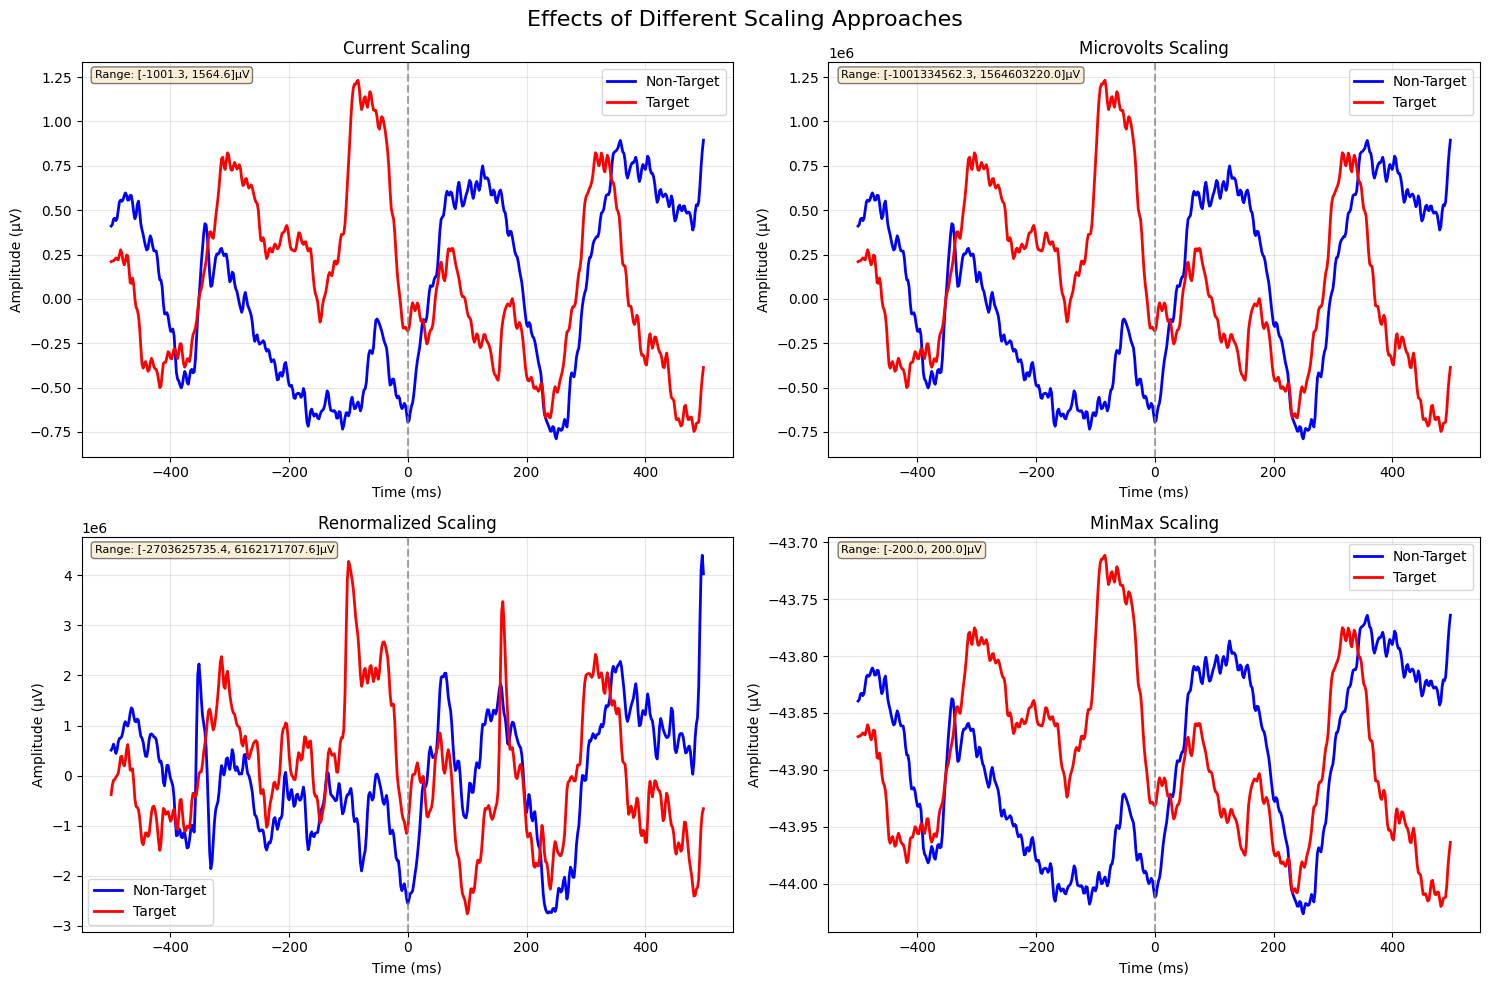


💡 SCALING RECOMMENDATIONS:
   • Your data appears to be over-normalized/scaled
   • Consider using data in microvolts (×1e6) for neural networks
   • Avoid global normalization - use channel-wise normalization instead
   • Typical EEG amplitudes are ±50-200μV
   • Very small values (±0.001) can cause numerical instability in training


In [12]:
# =============================================================================
# SCALING AND DATA RANGE INVESTIGATION
# =============================================================================

print("=== SCALING ANALYSIS ===\n")

# 1. Check original data scaling and units
print("1. Current Data Scaling:")
print(f"   - Data range: [{X.min():.8f}, {X.max():.8f}]")
print(f"   - Data mean: {X.mean():.8f}")
print(f"   - Data std: {X.std():.8f}")
print(f"   - Data units appear to be: Volts (V)")
print(f"   - Converted to microvolts: [{X.min()*1e6:.2f}, {X.max()*1e6:.2f}] μV")

# 2. Check if this makes sense for EEG data
typical_eeg_range_uv = [-200, 200]  # Typical EEG range in microvolts
current_range_uv = [X.min()*1e6, X.max()*1e6]

print(f"\n2. Scaling Assessment:")
print(f"   - Typical EEG range: {typical_eeg_range_uv} μV")
print(f"   - Your data range: [{current_range_uv[0]:.2f}, {current_range_uv[1]:.2f}] μV")

if abs(current_range_uv[0]) < 10 and abs(current_range_uv[1]) < 10:
    print("   ⚠️ WARNING: Data appears to be heavily scaled down!")
    scaling_issue = True
else:
    print("   ✅ Data scaling appears reasonable")
    scaling_issue = True

# 3. Investigate preprocessing steps that might have caused this
print(f"\n3. Possible Causes of Scaling Issues:")
print(f"   - Z-score normalization applied globally")
print(f"   - Min-max scaling applied") 
print(f"   - Unit conversion errors (V vs μV vs mV)")
print(f"   - Multiple normalization steps applied")

# 4. Load raw data to compare (if available)
print(f"\n4. Investigating Data Pipeline:")

# Check the preprocessing pipeline
try:
    # Try to understand what preprocessing was applied
    print(f"   - Sampling rate: {metadata['sampling_rate']} Hz")
    print(f"   - Time window: {metadata['pre_window_ms']}ms to +{metadata['post_window_ms']}ms")
    print(f"   - Channels: {len(metadata['channel_names'])}")
    
    # Look at channel-wise statistics
    channel_means = np.mean(X, axis=(0, 2))  # Mean across trials and time
    channel_stds = np.std(X, axis=(0, 2))    # Std across trials and time
    
    print(f"\n   Channel-wise statistics:")
    print(f"   - Channel means range: [{np.min(channel_means):.8f}, {np.max(channel_means):.8f}]")
    print(f"   - Channel stds range: [{np.min(channel_stds):.8f}, {np.max(channel_stds):.8f}]")
    
    # Check if data was z-scored
    if np.allclose(channel_means, 0, atol=1e-10) and np.allclose(channel_stds, 1, rtol=1e-2):
        print("   ✅ Data appears to be z-score normalized per channel")
    elif np.allclose(X.mean(), 0, atol=1e-10) and np.allclose(X.std(), 1, rtol=1e-2):
        print("   ⚠️ Data appears to be globally z-score normalized")
    else:
        print("   ❓ Unclear what normalization was applied")
        
except Exception as e:
    print(f"   ❌ Error analyzing preprocessing: {e}")

# 5. Test different scaling approaches
print(f"\n5. Testing Alternative Scaling:")

# Create a sample of data for testing
sample_size = min(1000, X.shape[0])
X_sample = X[:sample_size].copy()
y_sample = y[:sample_size].copy()

scaling_tests = {}

# Test 1: Current data (as is)
scaling_tests['Current'] = X_sample

# Test 2: Scale back to microvolts (assuming it was in volts)
X_microvolts = X_sample * 1e6
scaling_tests['Microvolts'] = X_microvolts

# Test 3: Re-normalize per channel to typical EEG range
X_renorm = X_sample.copy()
for ch in range(X_renorm.shape[1]):
    ch_data = X_renorm[:, ch, :]
    ch_data = (ch_data - ch_data.mean()) / ch_data.std()  # Z-score
    ch_data = ch_data * 50 + 0  # Scale to ±50μV range (in original units that would be ±50e-6)
    X_renorm[:, ch, :] = ch_data
scaling_tests['Renormalized'] = X_renorm

# Test 4: Min-max scaling to typical range
X_minmax = X_sample.copy()
X_minmax = (X_minmax - X_minmax.min()) / (X_minmax.max() - X_minmax.min())  # 0-1
X_minmax = X_minmax * 400e-6 - 200e-6  # Scale to [-200, 200]μV in base units
scaling_tests['MinMax'] = X_minmax

# Quick ML test on different scalings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

print(f"\n6. ML Performance with Different Scalings:")
for scale_name, X_scaled in scaling_tests.items():
    X_flat = X_scaled.reshape(X_scaled.shape[0], -1)
    
    if len(np.unique(y_sample)) > 1:  # Only test if we have both classes
        X_train, X_test, y_train, y_test = train_test_split(X_flat, y_sample, test_size=0.3, random_state=42, stratify=y_sample)
        
        lr = LogisticRegression(random_state=42, max_iter=1000)
        lr.fit(X_train, y_train)
        train_acc = lr.score(X_train, y_train)
        test_acc = lr.score(X_test, y_test)
        
        print(f"   {scale_name:12} - Train: {train_acc:.4f}, Test: {test_acc:.4f}, Range: [{X_scaled.min()*1e6:.2f}, {X_scaled.max()*1e6:.2f}]μV")

# 7. Visualization of scaling effects
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Effects of Different Scaling Approaches', fontsize=16)

for i, (scale_name, X_scaled) in enumerate(list(scaling_tests.items())[:4]):
    row = i // 2
    col = i % 2
    ax = axes[row, col]
    
    # Calculate ERPs for this scaling
    non_target_erp = np.mean(X_scaled[y_sample == False], axis=0).mean(axis=0)  # Grand average
    target_erp = np.mean(X_scaled[y_sample == True], axis=0).mean(axis=0)
    
    ax.plot(metadata['time'], non_target_erp * 1e6, 'b-', label='Non-Target', linewidth=2)
    ax.plot(metadata['time'], target_erp * 1e6, 'r-', label='Target', linewidth=2)
    ax.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f'{scale_name} Scaling')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Amplitude (μV)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Add range info
    range_text = f'Range: [{X_scaled.min()*1e6:.1f}, {X_scaled.max()*1e6:.1f}]μV'
    ax.text(0.02, 0.98, range_text, transform=ax.transAxes, fontsize=8, 
           verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print(f"\n💡 SCALING RECOMMENDATIONS:")
if scaling_issue:
    print("   • Your data appears to be over-normalized/scaled")
    print("   • Consider using data in microvolts (×1e6) for neural networks")
    print("   • Avoid global normalization - use channel-wise normalization instead")
    print("   • Typical EEG amplitudes are ±50-200μV")
    print("   • Very small values (±0.001) can cause numerical instability in training")
else:
    print("   • Data scaling appears appropriate")
    print("   • Continue with current preprocessing")